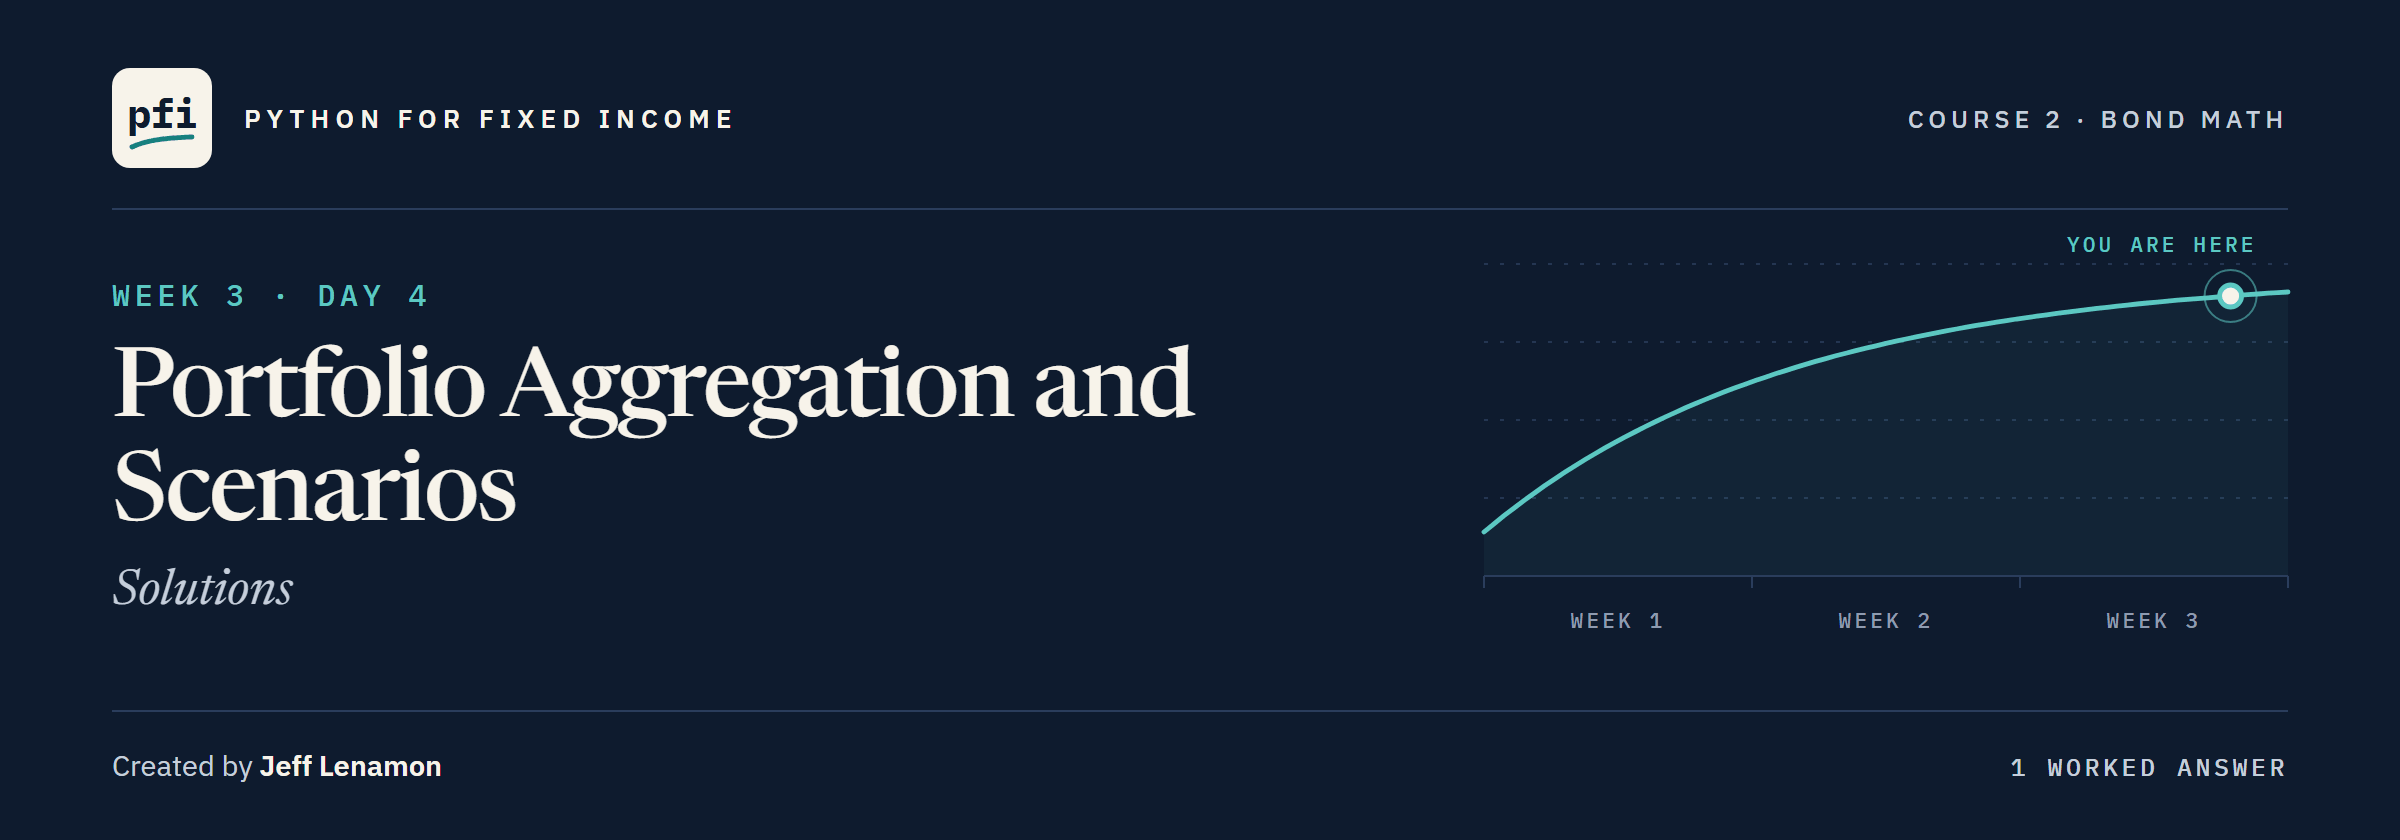

# Portfolio Aggregation and Scenarios: Solutions

Week 3, Day 4. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week3/day4/14_portfolio_aggregation_and_scenarios_solutions.ipynb)

## Exercises

Run the next cells first: the work folder with the module as this notebook ends it, the libraries and data, `check`, and the twenty bonds.

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/course02_bond_math/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}start_of_day/start_day.py
from start_day import start_day

# a new work folder: the Excel files, and the module and its tests as notebook 14 ends.
# To start the day again, restart the kernel and run all cells.
work = start_day(14, after=14)

Work folder pfi_course2_14_k4w7q2xr: 5 data files, the module as notebook 14 left it, 14 commits, tagged week1 and week2


In [2]:
import importlib

import bondmath
import pandas as pd

holdings = pd.read_csv('holdings.csv')
total_value = holdings['market_value'].sum()
print(len(holdings), 'positions,', f'{total_value:,.2f} dollars')

200 positions, 490,819,215.00 dollars


In [3]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [4]:
# notebook 12's twenty: every 30th benchmark bond the book does not hold
benchmark = pd.read_csv('benchmark.csv')
not_held = benchmark[~benchmark['cusip'].isin(holdings['cusip'])]
exercise_book = not_held.iloc[::30].head(20).reset_index(drop=True)
exercise_book['as_of_date'] = pd.to_datetime(exercise_book['as_of_date']).dt.date
exercise_book['maturity'] = pd.to_datetime(exercise_book['maturity']).dt.date
# the same face in every bond, in dollars
exercise_book['par_held'] = 1_000_000
print(len(exercise_book), 'bonds')

20 bonds


### Exercise 1

In [5]:
exercise_book['market_value'] = (exercise_book['par_held']
                                 * (exercise_book['price'] + exercise_book['accrued']) / 100)
bonds = list(zip(exercise_book['as_of_date'], exercise_book['maturity'], exercise_book['coupon'],
                 exercise_book['yield_pct']))
exercise_book['modified_bm'] = [bondmath.modified_duration(*bond) for bond in bonds]
ex1_market_value = exercise_book['market_value'].sum()
ex1_duration = bondmath.weighted_average(list(exercise_book['modified_bm']),
                                         list(exercise_book['market_value']))
check('Exercise 1 market value', ex1_market_value, 19891680.0)
check('Exercise 1 book duration', ex1_duration, 5.872304693449307)

Exercise 1 market value: correct
Exercise 1 book duration: correct


19,891,680.00 dollars for 20,000,000 of face, at a duration of 5.8723 years.

### Exercise 2

In [6]:
def reprice_twenty(new_yields_pct):
    """The twenty's change in dollars when every bond moves to its new yield."""
    change = 0.0
    for bond, new_yield_pct, par in zip(bonds, new_yields_pct, exercise_book['par_held']):
        settlement, maturity, coupon_pct, yield_pct = bond
        before = bondmath.dirty_price(settlement, maturity, coupon_pct, yield_pct)
        after = bondmath.dirty_price(settlement, maturity, coupon_pct, new_yield_pct)
        change += par * (after - before) / 100
    return change


ex2_down_100 = reprice_twenty(exercise_book['yield_pct'] - 1.0)
ex2_up_100 = reprice_twenty(exercise_book['yield_pct'] + 1.0)
check('Exercise 2 down 100 bp', ex2_down_100, 1227014.845920279)
check('Exercise 2 up 100 bp', ex2_up_100, -1114103.8557471745)

Exercise 2 down 100 bp: correct
Exercise 2 up 100 bp: correct


+1,227,014.85 down and -1,114,103.86 up: the fall gains 112,910.99 more, convexity again.

### Exercise 3

In [7]:
ex3_spread_pnl = reprice_twenty(exercise_book['yield_pct'] + 0.10 * exercise_book['oas'] / 100)
exercise_book['dts_bm'] = [bondmath.dts(bondmath.spread_duration(*bond), oas)
                           for bond, oas in zip(bonds, exercise_book['oas'])]
ex3_dts = bondmath.weighted_average(list(exercise_book['dts_bm']),
                                    list(exercise_book['market_value']))
check('Exercise 3 spreads up 10 percent', ex3_spread_pnl, -151874.70737842587)
check('Exercise 3 book DTS', ex3_dts, 768.3161885533202)

Exercise 3 spreads up 10 percent: correct
Exercise 3 book DTS: correct


-151,874.71 dollars; DTS 768.32 says about -0.768 percent of the value, and the full reprice is a little less.

### Exercise 4

In [8]:
%%writefile -a bondmath.py


def scenario_pnl_dollars(par: float, dirty_price_before: float, dirty_price_after: float) -> float:
    """Change in a position's market value under a scenario, in dollars.

    Units: par in dollars of face; both dirty prices per 100 of face. The result is in dollars,
    positive for a gain. Convention: par x (dirty_price_after - dirty_price_before) / 100.
    Excel: =par*(after-before)/100
    """
    return par * (dirty_price_after - dirty_price_before) / 100

Appending to bondmath.py


In [9]:
%%writefile -a test_bondmath.py


def test_scenario_pnl_dollars_known_case():
    # 1,000,000 of face from 101.50 to 100.25: 1.25 per 100 lost is 12,500 dollars
    assert bondmath.scenario_pnl_dollars(1_000_000, 101.50, 100.25) == pytest.approx(-12_500.0, abs=1e-9)
    # nothing moves, nothing changes
    assert bondmath.scenario_pnl_dollars(5_000_000, 99.0, 99.0) == 0.0

Appending to test_bondmath.py


In [10]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', '--tb=no']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.........................................                                [100%]
41 passed in 0.50s



In [11]:
importlib.reload(bondmath)
ex4_up_25 = 0.0
for bond, par in zip(bonds, exercise_book['par_held']):
    settlement, maturity, coupon_pct, yield_pct = bond
    before = bondmath.dirty_price(settlement, maturity, coupon_pct, yield_pct)
    after = bondmath.dirty_price(settlement, maturity, coupon_pct, yield_pct + 0.25)
    ex4_up_25 += bondmath.scenario_pnl_dollars(par, before, after)
check('Exercise 4 up 25 bp', ex4_up_25, -288540.79312331806)

Exercise 4 up 25 bp: correct


41 tests pass, and the twenty lose 288,540.79 dollars for every yield +25 bp.

### Exercise 5: AI check

In [12]:
def assistant_market_value_weights_pct(par_held, clean_price, accrued):
    """Market-value weight of each position in the book, in percent.

    Units: par_held in dollars of face; clean_price and accrued per 100 of face. The result is a
    list of percents that sums to 100. Convention: market value = par_held x (clean_price +
    accrued) / 100, on the dirty price, as in the file's market_value. Excel: =R2*(I2+K2)/100
    """
    market_values = []
    # the fix: walk accrued too, and value each position on the dirty price
    for par, price, interest in zip(par_held, clean_price, accrued):
        market_values.append(par * (price + interest) / 100)
    total = sum(market_values)
    return [value / total * 100 for value in market_values]

In [13]:
weights_pct = assistant_market_value_weights_pct(list(holdings['par_held']),
                                                 list(holdings['price']),
                                                 list(holdings['accrued']))
expected_pct = holdings['market_value'] / total_value * 100
for cusip, weight, expected in zip(holdings['cusip'], weights_pct, expected_pct):
    assert abs(weight - expected) < 1e-9, f'{cusip}: {weight:.6f} percent, the file {expected:.6f}'
ex5_first_weight = weights_pct[0]
ex5_book_duration = bondmath.weighted_average(list(holdings['duration']), weights_pct)
check('Exercise 5 first weight', ex5_first_weight, 1.1074342311557628)
check('Exercise 5 book duration', ex5_book_duration, 6.254777411342789)

Exercise 5 first weight: correct
Exercise 5 book duration: correct


The assistant valued each position on the clean price and never used `accrued`: Bezane got 1.104779 percent where the file gives 1.107434.
The weights still add up to 100, which is why it looked harmless; the test from the file caught it on the first row.

[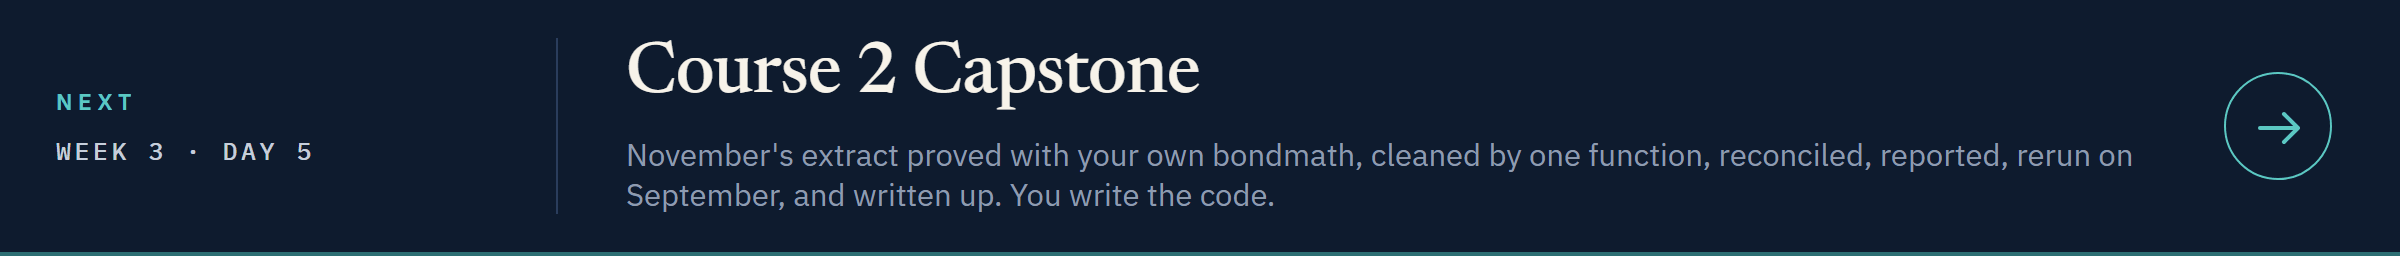](../day5/course2_capstone.ipynb)

[Open Day 5 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week3/day5/course2_capstone.ipynb)